In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import config as c

## let's check if memmap works (loading by indices)

In [2]:
fpr = np.memmap(c.signals_path, 
                dtype = c.dtype, 
                mode = 'r', #only reading
                shape = (c.N_exams, c.N_windows, c.N_channels, c.Window_len*c.Fs))

### shape & choice check

In [3]:
fpr[150].shape

(150, 17, 768)

In [4]:
single_exam = fpr[12]

### units check (expected Volts, so 1e-6 or 1e-5 in notation)

In [5]:
single_exam

memmap([[[ 7.31615955e-06,  1.61414810e-05, -2.46526241e-07, ...,
          -1.41685700e-06, -1.31374372e-05, -1.44678916e-05],
         [ 9.83872233e-05, -9.67456872e-05, -3.75783529e-05, ...,
           3.47313062e-06, -6.16046373e-06, -8.97009522e-06],
         [ 5.76640059e-06,  2.38447556e-05,  1.31631978e-05, ...,
          -4.73265693e-08, -9.42359293e-06, -1.00679008e-05],
         ...,
         [ 2.68767849e-06,  7.73559532e-06,  3.23031918e-06, ...,
          -1.58775890e-06, -1.52806683e-06, -6.39402469e-06],
         [ 1.79572191e-06,  8.27957683e-06,  5.27471457e-06, ...,
           9.57530847e-06,  8.23160553e-06,  4.52106769e-06],
         [ 4.20297829e-06,  6.67064478e-06,  7.20168509e-06, ...,
           1.24302051e-06, -6.88946898e-07, -5.20456479e-06]],

        [[ 5.12025736e-07,  9.43603845e-06,  4.69715360e-06, ...,
           1.70344701e-05,  2.90411640e-06, -4.63572042e-06],
         [ 1.69868656e-06,  1.13430378e-05,  1.29529280e-05, ...,
           1.11625413e

### check how it looks on plot (use MNE for readability and epoch alignement)

Not setting metadata
150 matching events found
No baseline correction applied
0 projection items activated
Using matplotlib as 2D backend.


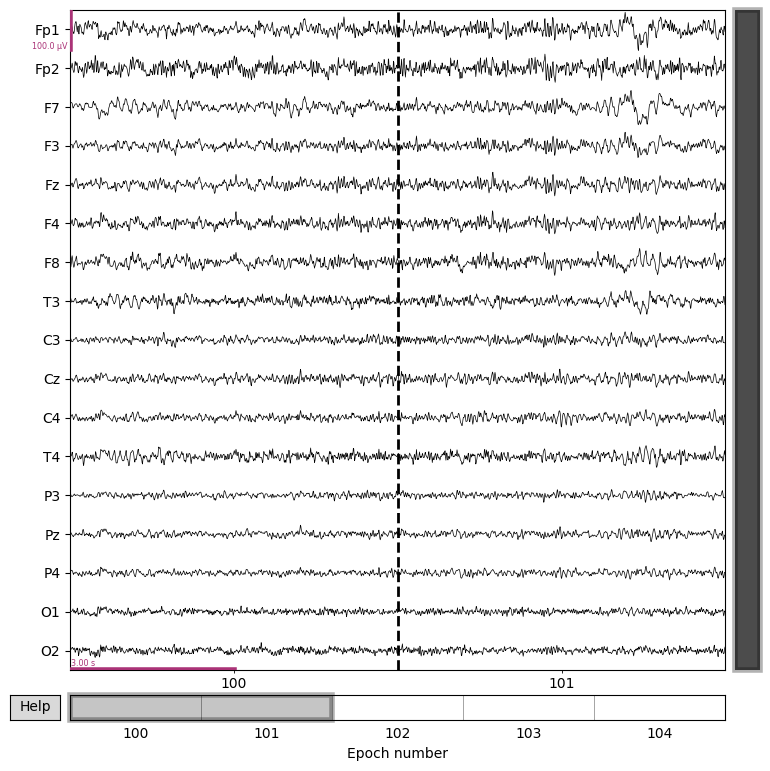

In [6]:
import mne

info = mne.create_info(['Fp1','Fp2','F7','F3','Fz','F4','F8','T3','C3','Cz','C4','T4','P3','Pz','P4','O1','O2'], sfreq=128, ch_types="eeg")  
epochs = mne.EpochsArray(single_exam, info, tmin=0, baseline=None)
g = epochs[100:105].plot(n_epochs=2, scalings=dict(eeg=50e-6))


### check psd

Set montage to plot psd with channels labeling and sensors annotations on topological head.

In [7]:
epochs.set_montage("colin27_1020")

<EpochsArray | 150 events (all good), 0 – 5.992 s (baseline off), ~15.0 MiB, data loaded,
 '1': 150>

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


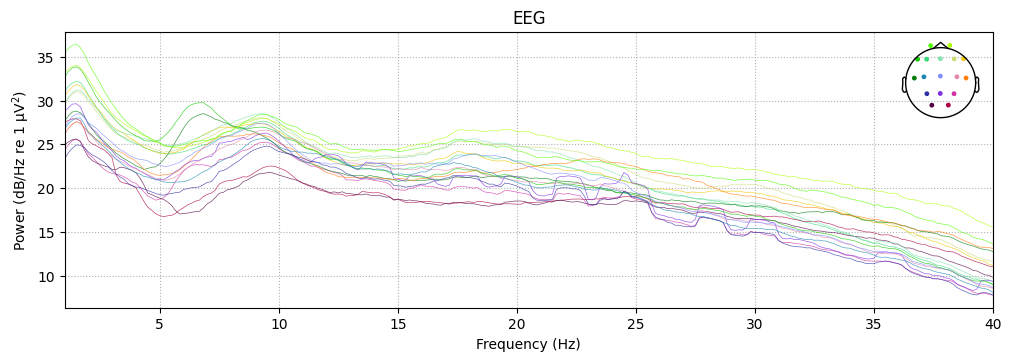

In [8]:
g = epochs.plot_psd(fmin = 1, fmax = 40, picks = "eeg", spatial_colors=True)

## explore dataset splitting methods

Comment from scikit-learn:
- Choosing the right cross-validation object is a crucial part of fitting a model properly. 
- There are **many** ways to split data into training and test sets in order to avoid model overfitting, to standardize the number of groups in test sets, etc.

In the multi-site dataset it is very important to avoid leakage and split by site groups with demographics and label stratification.

### load metadata (aligned with eeg database per indices)

In [9]:
meta = pd.read_csv(c.metadata_path)
meta

,site,patient_id,exam_id,age,age_group,female,pathology
0,S00,P27809,20220512-164523-{3222752a-e1a1-439f-b7a7-85642...,56.9,56-65,0,0
1,S00,P27811,20220512-164615-{ee327e54-0056-41d9-84a4-a4243...,31.2,26-35,0,0
2,S00,P27812,20220512-164352-{310806e9-34f6-4c9e-9478-1726b...,31.2,26-35,0,0
3,S00,P27818,20220512-164324-{d7f16f2a-5bb3-47e8-80fc-76fa5...,40.2,36-45,1,0
4,S00,P27819,20220512-164255-{8efca8a5-c0f8-4ceb-b0b4-e3ade...,39.2,36-45,1,0
...,...,...,...,...,...,...,...
34826,S29,P25495,20220602-152957-{d652f74d-ea3e-4fcd-afe6-fa624...,16.6,16-25,1,0
34827,S29,P25494,20220602-152950-{328256db-ecb9-4880-aea3-cae0d...,59.5,56-65,1,1
34828,S29,P25493,20220602-153022-{951c8fc9-e8b4-4a85-9c3b-c8cea...,59.7,56-65,1,1
34829,S29,P25492,20220602-153237-{eec9357c-2477-4e02-a5f0-13641...,17.2,16-25,1,0


In [10]:
y = meta['pathology']
y

0        0
1        0
2        0
3        0
4        0
        ..
34826    0
34827    1
34828    1
34829    0
34830    0
Name: pathology, Length: 34831, dtype: int64

In [11]:
groups = meta['site']

In [12]:
unique_groups = list(groups)
group_mapping = {g: i for i, g in enumerate(unique_groups)}
group_indices = [group_mapping[g] for g in groups]

### create color pallette to capture all sites on the split bar

In [13]:
# Source - https://stackoverflow.com/a/59998512
# Posted by Greg0ry, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-10, License - CC BY-SA 4.0

import math
from matplotlib.colors import ListedColormap
from matplotlib.cm import hsv #type:ignore


def generate_colormap(number_of_distinct_colors: int = 30):
    if number_of_distinct_colors == 0:
        number_of_distinct_colors = 80

    number_of_shades = 7
    number_of_distinct_colors_with_multiply_of_shades = int(math.ceil(number_of_distinct_colors / number_of_shades) * number_of_shades)
    linearly_distributed_nums = np.arange(number_of_distinct_colors_with_multiply_of_shades) / number_of_distinct_colors_with_multiply_of_shades
    arr_by_shade_rows = linearly_distributed_nums.reshape(number_of_shades, number_of_distinct_colors_with_multiply_of_shades // number_of_shades)
    arr_by_shade_columns = arr_by_shade_rows.T
    number_of_partitions = arr_by_shade_columns.shape[0]
    nums_distributed_like_rising_saw = arr_by_shade_columns.reshape(-1)

    # HSV colour map is cyclic (https://matplotlib.org/tutorials/colors/colormaps.html#cyclic)
    initial_cm = hsv(nums_distributed_like_rising_saw)

    lower_partitions_half = number_of_partitions // 2
    upper_partitions_half = number_of_partitions - lower_partitions_half
    lower_half = lower_partitions_half * number_of_shades
    for i in range(3):
        initial_cm[0:lower_half, i] *= np.arange(0.2, 1, 0.8/lower_half)
    for i in range(3):
        for j in range(upper_partitions_half):
            modifier = np.ones(number_of_shades) - initial_cm[lower_half + j * number_of_shades: lower_half + (j + 1) * number_of_shades, i]
            modifier = j * modifier / upper_partitions_half
            initial_cm[lower_half + j * number_of_shades: lower_half + (j + 1) * number_of_shades, i] += modifier

    return ListedColormap(initial_cm)

In [14]:
cmap_data = generate_colormap()
cmap_cv = plt.cm.coolwarm #type:ignore
n_splits = 5

def visualize_groups(classes, groups):

    fig, ax = plt.subplots(figsize = (15, 8))
    ax.scatter(
        range(len(groups)),
        [0.5] * len(groups),
        c=groups,
        marker="_",
        lw=50,
        cmap=cmap_data,
    )
    ax.scatter(
        range(len(groups)),
        [3.5] * len(groups),
        c=classes,
        marker="_",
        lw=50,
        cmap=cmap_cv,
    )
    ax.set(
        ylim=[-1, 5],
        yticks=[0.5, 3.5],
        yticklabels=["Sites", "Labels"],
        xlabel="Exam index",
    )
    return fig

f = visualize_groups(y, group_indices)

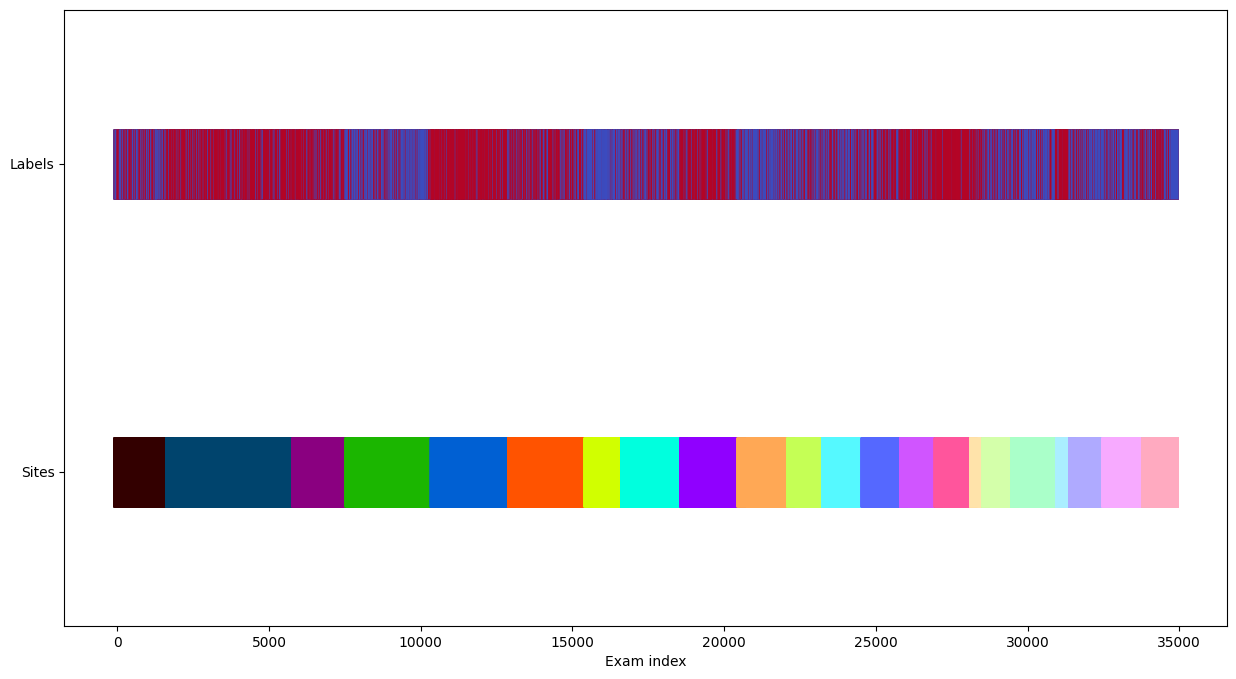

In [15]:
f

In [ ]:
def plot_cv_indices(cv, X, y, group_indices, ax, n_splits, lw=10):
    """Create a sample plot for indices of a cross-validation object."""
    for ii, (tr, tt) in enumerate(cv.split(X=X, y=y, groups=group_indices)):

        indices = np.array([np.nan] * len(X))
        indices[tt] = 1
        indices[tr] = 0

        ax.scatter(
            range(len(indices)),
            [ii + 0.5] * len(indices),
            c=indices,
            marker="_",
            lw=lw,
            cmap=cmap_cv,
            vmin=-0.2,
            vmax=1.2,
        )

    ax.scatter(range(len(X)), [ii + 1.5] * len(X), c=y, marker="_", lw=lw, cmap=cmap_cv) #type:ignore
    ax.scatter(range(len(X)), [ii + 2.5] * len(X), c=group_indices, marker="_", lw=lw, cmap=cmap_data) #type:ignore
    yticklabels = list(range(n_splits)) + ["Labels", "Sites"]
    ax.set(
        yticks=np.arange(n_splits + 2) + 0.5,
        yticklabels=yticklabels,
        xlabel="Sample index",
        ylabel="CV iteration",
        ylim=[n_splits + 2.2, -0.2],
        xlim=[0, len(X)])
    ax.set_title("{}".format(type(cv).__name__), fontsize=15)
    return ax

In [17]:
from sklearn.model_selection import (GroupKFold,
                                     GroupShuffleSplit,
                                     KFold,
                                     ShuffleSplit,
                                     StratifiedGroupKFold,
                                     StratifiedKFold,
                                     StratifiedShuffleSplit,
                                     TimeSeriesSplit)

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


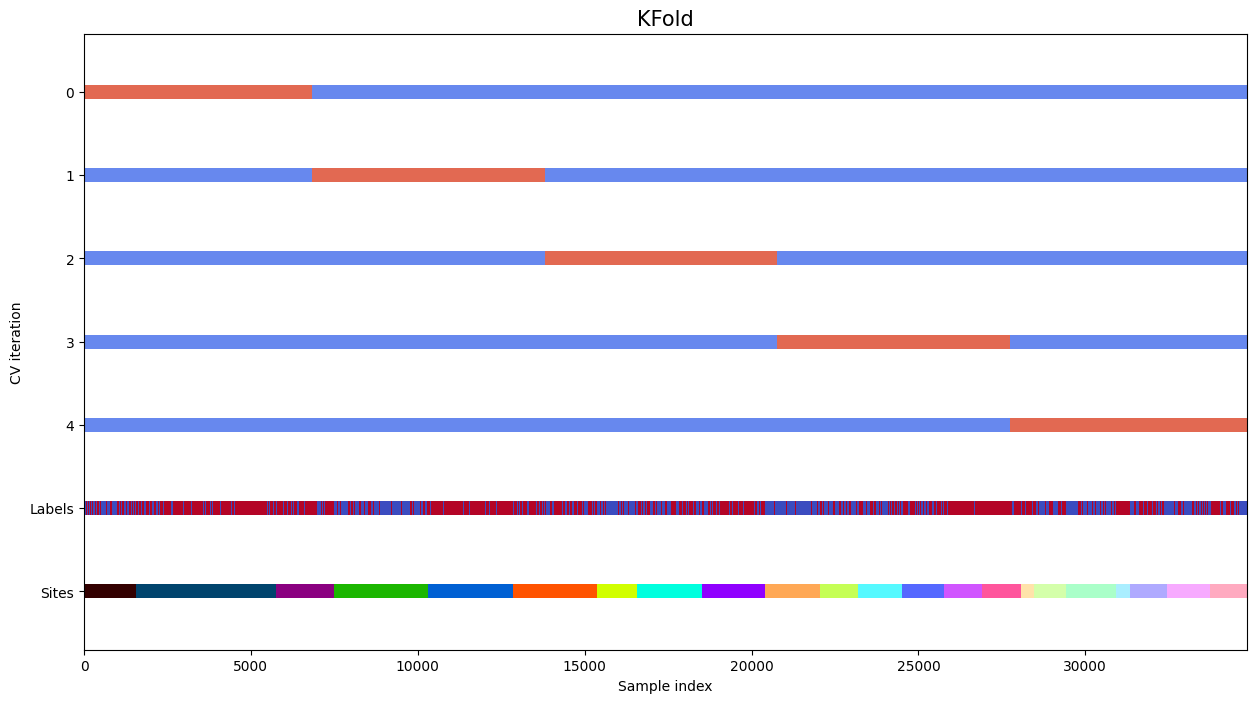

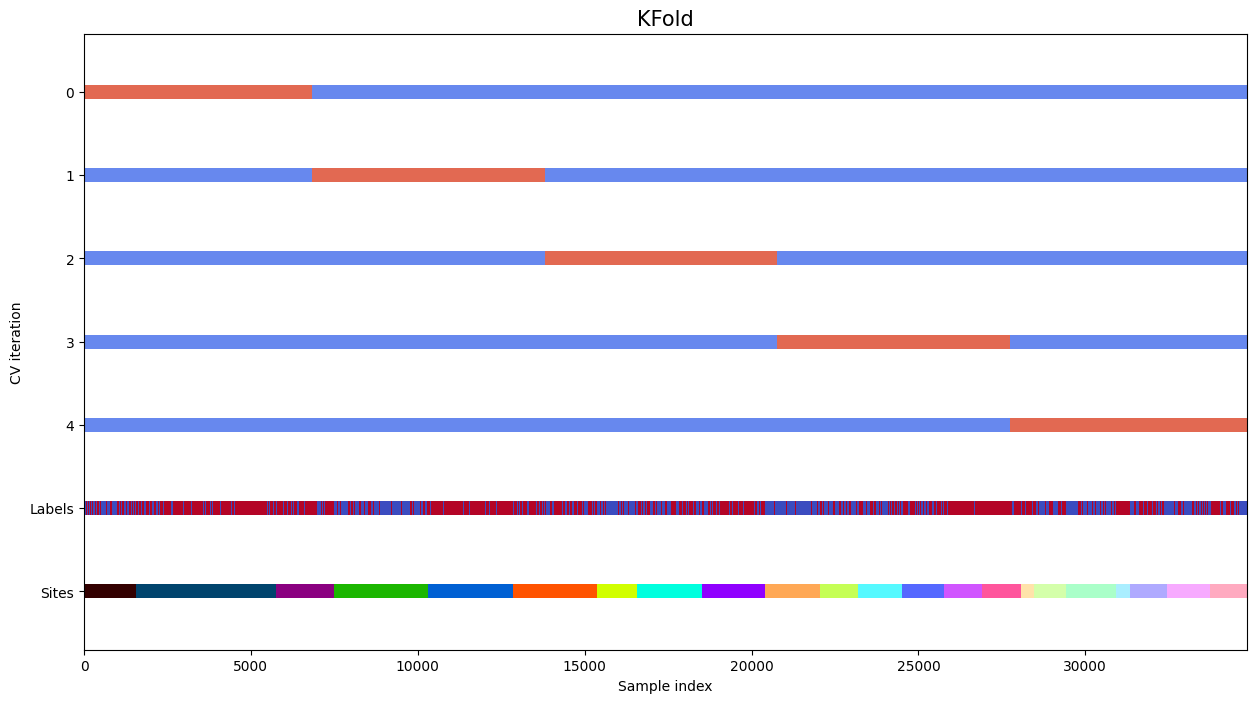

In [20]:
_, ax = plt.subplots(figsize = (15,8))
cv = KFold(n_splits)
g = plot_cv_indices(cv, fpr, y, group_indices, ax = ax, n_splits = n_splits)
plt.show()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:883: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


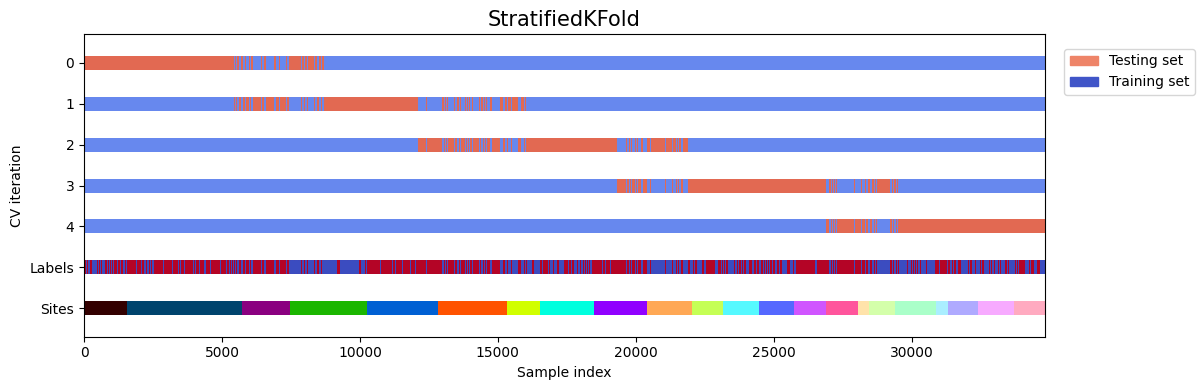

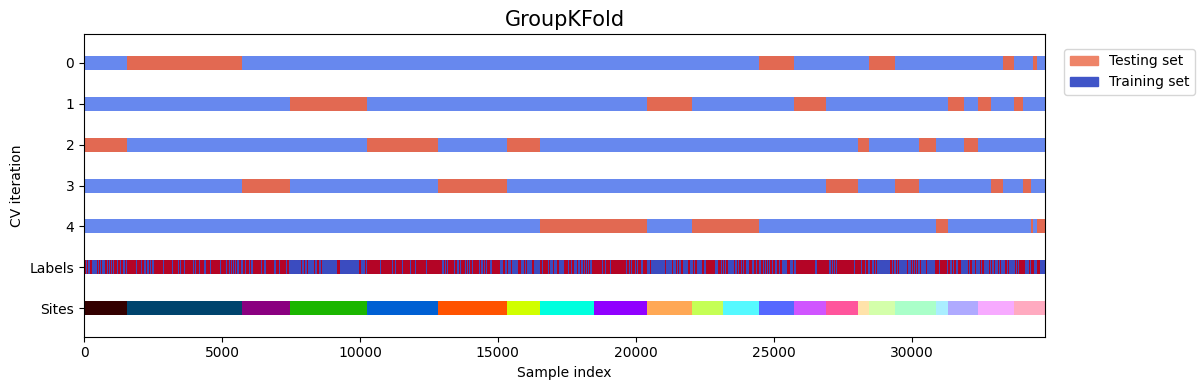

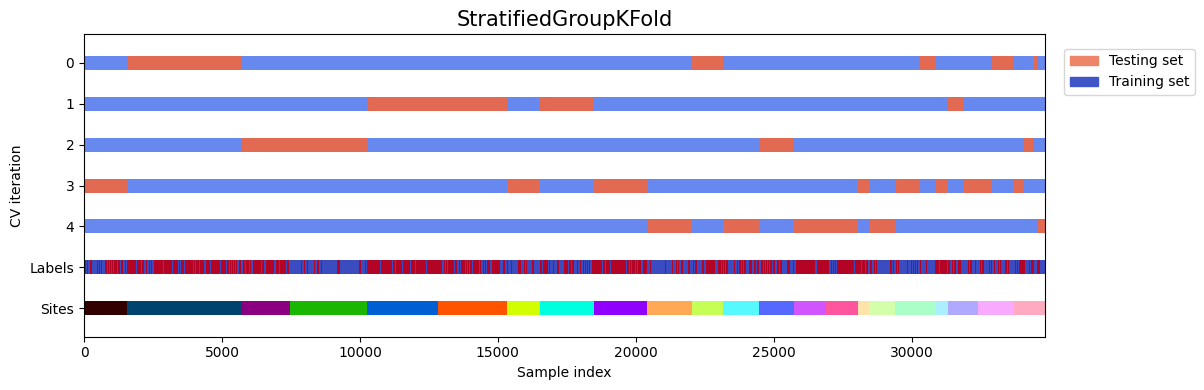

In [21]:
cvs = [StratifiedKFold, GroupKFold, StratifiedGroupKFold]

for cv in cvs:
    fig, ax = plt.subplots(figsize=(15, 4))
    plot_cv_indices(cv(n_splits), fpr, y, group_indices, ax, n_splits)
    ax.legend(
        [Patch(color=cmap_cv(0.8)), Patch(color=cmap_cv(0.02))],
        ["Testing set", "Training set"],
        loc=(1.02, 0.8),
    )
    # Make the legend fit
    plt.tight_layout()
    g = fig.subplots_adjust(right=0.7)
plt.show()

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by ShuffleSplit
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:883: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:2425: UserWarning: The groups parameter is ignored by StratifiedShuffleSplit
  warnings.warn(
/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/sklearn/model_selection/_split.py:1255: UserWarning: The groups parameter is ignored by TimeSeriesSplit
  warnings.warn(


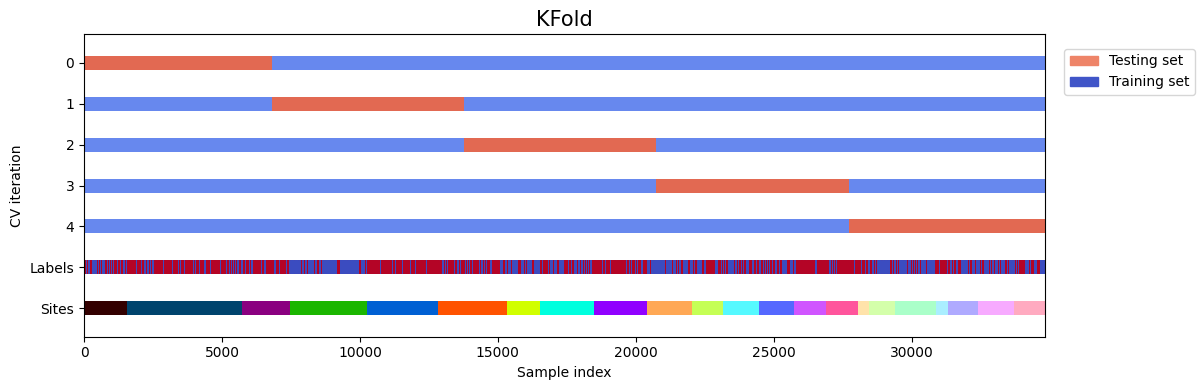

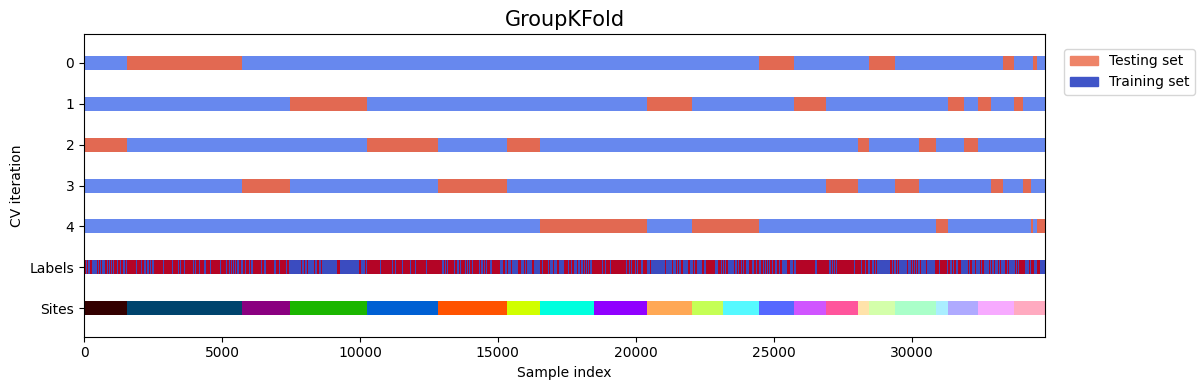

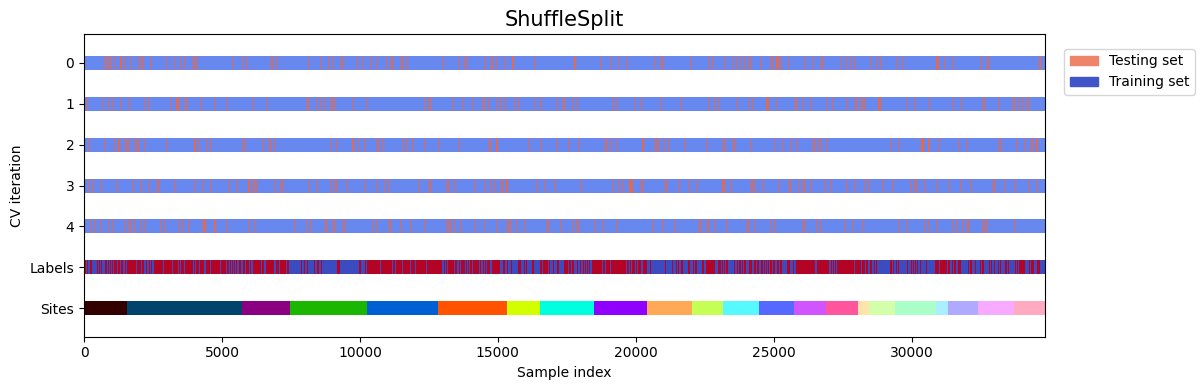

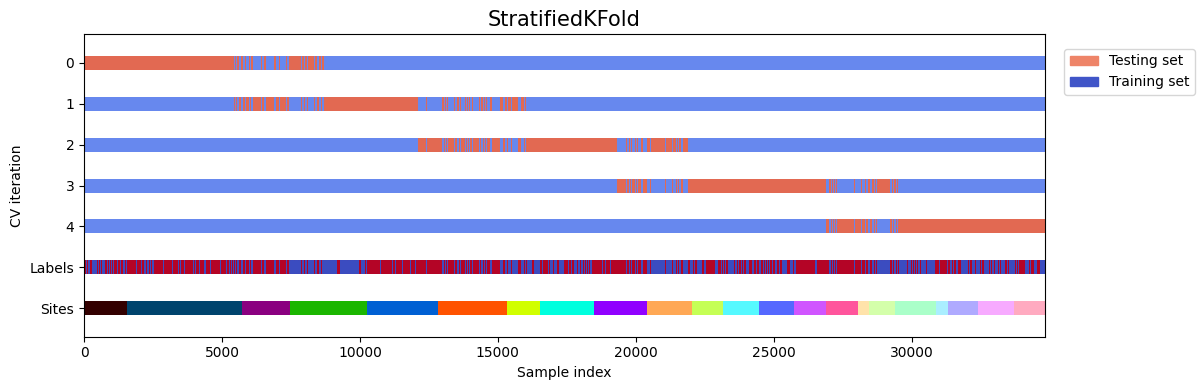

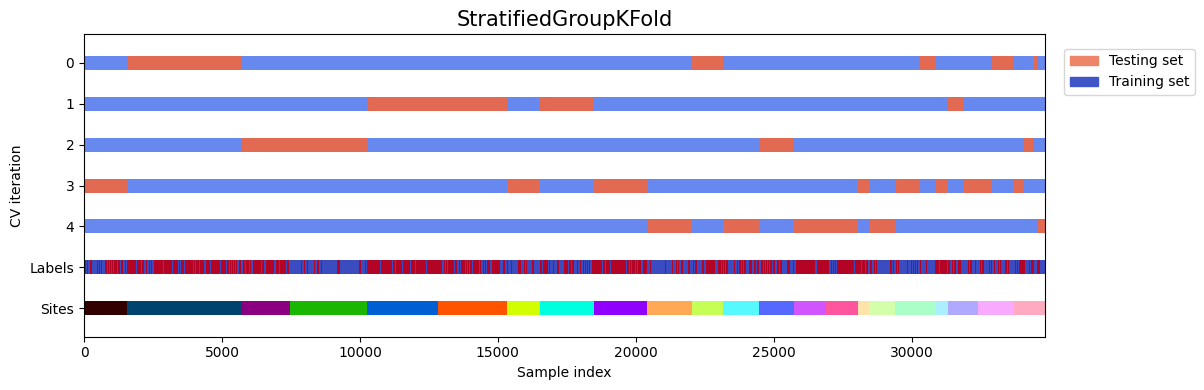

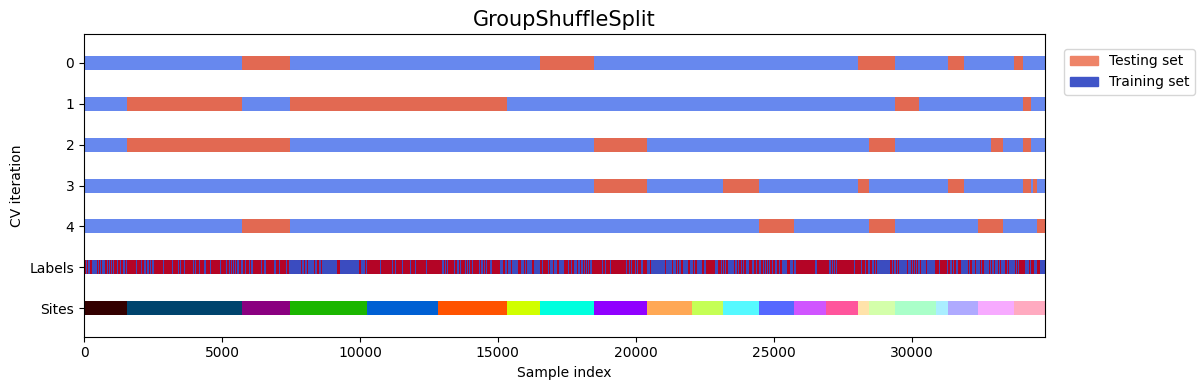

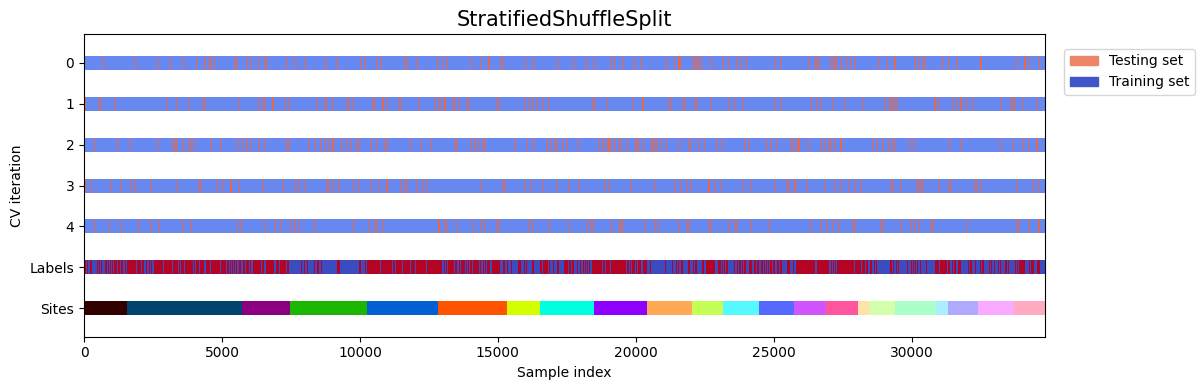

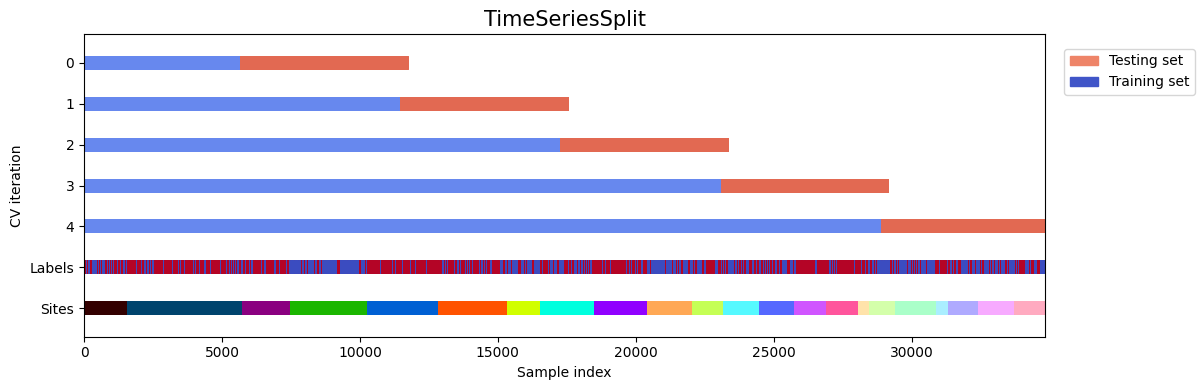

In [22]:
cvs = [
    KFold,
    GroupKFold,
    ShuffleSplit,
    StratifiedKFold,
    StratifiedGroupKFold,
    GroupShuffleSplit,
    StratifiedShuffleSplit,
    TimeSeriesSplit,
]


for cv in cvs:
    this_cv = cv(n_splits=n_splits)
    fig, ax = plt.subplots(figsize=(15, 4))
    plot_cv_indices(this_cv, fpr, y, group_indices, ax, n_splits)

    ax.legend(
        [Patch(color=cmap_cv(0.8)), Patch(color=cmap_cv(0.02))],
        ["Testing set", "Training set"],
        loc=(1.02, 0.8),
    )
    # Make the legend fit
    plt.tight_layout()
    fig.subplots_adjust(right=0.7)
plt.show()

There is a distinct difference between methods with grouping and they shall be used for all site dataset.